# Módulo 27 · Práctica: optimización geométrica y software 3D

En los apuntes del módulo 27 un optimizador geométrico es siempre la misma cadena: **parámetros → geometría → simulador o renderizador → pérdida → gradiente**. En esta práctica construirás cada eslabón con datos sintéticos y verás los casos de estudio de los seis temas funcionando en una CPU en menos de un minuto.

| Parte | Qué haces | Tema de los apuntes |
| --- | --- | --- |
| 0 | Preparación | — |
| 1 | Funciones de distancia con signo y ajuste de una esfera a un escaneo | Tema 1 |
| 2 | Optimización de topología SIMP de la viga MBB (código de 88 líneas en numpy) | Tema 2 |
| 3 | Aleta disipadora: simulador, sustituto neuronal y simulador diferenciable | Tema 3 |
| 4 | Ajuste de una forma 3D a siluetas con rasterización suave | Tema 4 |
| 5 | Simplificación QEM, niveles de detalle con presupuesto y memoria de texturas | Tema 5 |
| 6 | Validación de mallas generadas | Tema 6 |
| 7 | Retos | — |

Las celdas marcadas con `# TU CÓDIGO` son ejercicios; cada una va seguida de una comprobación con `assert`. Para que el cuaderno se ejecute de principio a fin, la versión guardada trae rellenada la solución de referencia: bórrala y escribe la tuya. Las soluciones se repiten, comentadas, al final.

**Dependencias:** numpy, scipy, matplotlib, scikit-learn y torch (solo para las partes 3c y 4). No se descarga nada: todos los datos se generan aquí con semillas fijas.

## Parte 0 · Preparación

In [1]:
# Si falta algo:  !pip install numpy scipy matplotlib scikit-learn torch
import time, heapq, itertools
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
from scipy.linalg import solve_banded
from scipy.optimize import brentq
from scipy.stats import qmc
from scipy.special import sph_harm_y
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import torch
torch.set_num_threads(1)
T0 = time.time()
print("numpy", np.__version__, "· torch", torch.__version__)

numpy 2.5.3 · torch 2.14.1+cu130


## Parte 1 · Funciones de distancia con signo (tema 1)

Una SDF devuelve la distancia con signo a la superficie: negativa dentro, positiva fuera. Para una esfera de centro $c$ y radio $r$, $f(x)=\lVert x-c\rVert-r$. Las operaciones booleanas son mínimos y máximos (apuntes, tema 1): unión $\min(f_1,f_2)$, intersección $\max(f_1,f_2)$ y diferencia $\max(f_1,-f_2)$.

**Ejercicio 1.** Completa `sdf_esfera`, `sdf_caja` (caja alineada con los ejes de semilados `b`) y las tres operaciones.

In [2]:
def sdf_esfera(x, c, r):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    return np.linalg.norm(x - c, axis=-1) - r

def sdf_caja(x, b):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    q = np.abs(x) - b
    return np.linalg.norm(np.maximum(q, 0), axis=-1) + np.minimum(q.max(axis=-1), 0)

def union(f1, f2): return np.minimum(f1, f2)
def interseccion(f1, f2): return np.maximum(f1, f2)
def diferencia(f1, f2): return np.maximum(f1, -f2)

Correcto: f_esfera = [-20.  10. -10.] · f_caja = [-5. 20.  5.]


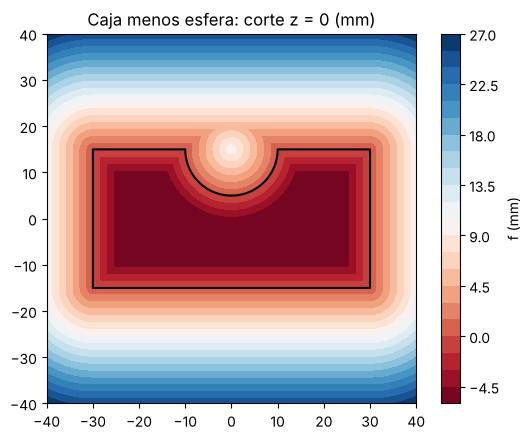

In [3]:
# Comprobación
p = np.array([[0., 0, 0], [30, 0, 0], [0, 0, 10]])
fe = sdf_esfera(p, np.zeros(3), 20.0)
fb = sdf_caja(p, np.array([10., 10, 5]))
assert np.allclose(fe, [-20, 10, -10]) and np.allclose(fb, [-5, 20, 5])
assert np.allclose(diferencia(fb, fe), [20, 20, 10])
# |∇f| = 1 (ecuación eikonal) comprobado por diferencias finitas fuera del centro
x0, h_ = np.array([3., 4, 12]), 1e-6
g = np.array([(sdf_esfera(x0 + h_*e, np.zeros(3), 5) - sdf_esfera(x0 - h_*e, np.zeros(3), 5)) / (2*h_) for e in np.eye(3)])
assert abs(np.linalg.norm(g) - 1) < 1e-6
print("Correcto: f_esfera =", fe, "· f_caja =", fb)
g2 = np.linspace(-40, 40, 241); XX, YY = np.meshgrid(g2, g2)
P2 = np.stack([XX, YY, np.zeros_like(XX)], -1)
F2 = diferencia(sdf_caja(P2, np.array([30., 15, 5])), sdf_esfera(P2, np.array([0., 15, 0]), 10))
cs = plt.contourf(XX, YY, F2, 30, cmap="RdBu"); plt.colorbar(cs, label="f (mm)"); plt.contour(XX, YY, F2, [0], colors="k")
plt.gca().set_aspect("equal"); plt.title("Caja menos esfera: corte z = 0 (mm)"); plt.show()

### Ajuste de una esfera a un escaneo parcial

Caso de estudio del tema 1: un escáner devuelve 300 puntos de un casquete de 40° de una esfera de radio 25 mm centrada en (12, −5, 30) mm, con ruido gaussiano de σ = 0,5 mm. Comparamos el ajuste **algebraico** (lineal, rápido) con el ajuste **geométrico**, que minimiza los residuos de la SDF, $\sum_i(\lVert x_i-c\rVert-r)^2$, por Gauss–Newton.

In [4]:
rng = np.random.default_rng(0)
c_real, r_real, n_pts = np.array([12., -5., 30.]), 25.0, 300
u = rng.uniform(np.cos(np.radians(40)), 1, n_pts); ph = rng.uniform(0, 2 * np.pi, n_pts)
d = np.stack([np.sqrt(1 - u**2) * np.cos(ph), np.sqrt(1 - u**2) * np.sin(ph), u], 1)
X = c_real + r_real * d + rng.normal(0, 0.5, (n_pts, 3))
print(X.shape, "puntos; primer punto (mm):", X[0].round(2))

(300, 3) puntos; primer punto (mm): [ 19.98 -11.49  52.44]


**Ejercicio 2.** Ajuste algebraico: como $\lVert x\rVert^2 = 2c\cdot x + (r^2-\lVert c\rVert^2)$ es **lineal** en $(c,\,k=r^2-\lVert c\rVert^2)$, resuélvelo por mínimos cuadrados (módulo 8) y recupera $r=\sqrt{k+\lVert c\rVert^2}$.

**Ejercicio 3.** Ajuste geométrico: itera Gauss–Newton con residuos $\rho_i=\lVert x_i-c\rVert-r$ y jacobiano $J_i=\bigl(-(x_i-c)^\top/\lVert x_i-c\rVert,\;-1\bigr)$, partiendo del ajuste algebraico.

In [5]:
def ajuste_algebraico(X):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    A = np.c_[2 * X, np.ones(len(X))]; b = (X**2).sum(1)
    sol = np.linalg.lstsq(A, b, rcond=None)[0]
    c = sol[:3]
    return c, np.sqrt(sol[3] + c @ c)

def ajuste_geometrico(X, c0, r0, iters=30, tol=1e-10):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    p = np.r_[c0, r0]
    for k in range(iters):
        D = X - p[:3]; nr = np.linalg.norm(D, axis=1); res = nr - p[3]
        J = np.c_[-D / nr[:, None], -np.ones(len(X))]
        dp = np.linalg.lstsq(J, -res, rcond=None)[0]; p = p + dp
        if np.linalg.norm(dp) < tol: break
    return p[:3], p[3], k + 1

In [6]:
# Comprobación
rms = lambda c, r: np.sqrt(np.mean((np.linalg.norm(X - c, axis=1) - r) ** 2))
c_a, r_a = ajuste_algebraico(X)
c_g, r_g, it_g = ajuste_geometrico(X, c_a, r_a)
print(f"algebraico: r = {r_a:.3f} mm, error del centro = {np.linalg.norm(c_a - c_real):.3f} mm, RMS = {rms(c_a, r_a):.4f} mm")
print(f"geométrico: r = {r_g:.3f} mm, error del centro = {np.linalg.norm(c_g - c_real):.3f} mm, RMS = {rms(c_g, r_g):.4f} mm ({it_g} iteraciones)")
assert abs(r_a - 23.977) < 0.01 and abs(r_g - 25.418) < 0.01
assert rms(c_g, r_g) < rms(c_a, r_a)
print("Correcto: el ajuste algebraico subestima el radio en un casquete; el geométrico reduce el error del radio de 1,02 a 0,42 mm.")

algebraico: r = 23.977 mm, error del centro = 1.240 mm, RMS = 0.4908 mm
geométrico: r = 25.418 mm, error del centro = 0.390 mm, RMS = 0.4768 mm (8 iteraciones)
Correcto: el ajuste algebraico subestima el radio en un casquete; el geométrico reduce el error del radio de 1,02 a 0,42 mm.


## Parte 2 · Optimización de topología SIMP (tema 2)

Traducimos a numpy el código de 88 líneas de Andreassen *et al.* (2011). Problema: minimizar la flexibilidad $c(x)=F^\top U$ de la semiviga MBB de 60 × 20 elementos con fracción de volumen 0,5, sujeta a $K(\tilde x)U=F$. Interpolación SIMP modificada:

$$E_e = E_{\min} + \tilde x_e^{\,p}\,(E_0-E_{\min}),\qquad \frac{\partial c}{\partial \tilde x_e} = -p\,\tilde x_e^{\,p-1}(E_0-E_{\min})\,u_e^\top k_0 u_e .$$

La sensibilidad sale del método adjunto: la flexibilidad es autoadjunta, $\lambda=U$ (apuntes, tema 2).

In [7]:
def ke_q4(nu=0.3):
    # matriz de rigidez del elemento cuadrado bilineal con E = 1 (Andreassen et al., 2011, §3.1)
    A11 = np.array([[12, 3, -6, -3], [3, 12, 3, 0], [-6, 3, 12, -3], [-3, 0, -3, 12]])
    A12 = np.array([[-6, -3, 0, 3], [-3, -6, -3, -6], [0, -3, -6, 3], [3, -6, 3, -6]])
    B11 = np.array([[-4, 3, -2, 9], [3, -4, -9, 4], [-2, -9, -4, -3], [9, 4, -3, -4]])
    B12 = np.array([[2, -3, 4, -9], [-3, 2, 9, -2], [4, 9, 2, 3], [-9, -2, 3, 2]])
    return 1 / (1 - nu**2) / 24 * (np.block([[A11, A12], [A12.T, A11]]) + nu * np.block([[B11, B12], [B12.T, B11]]))

KE = ke_q4()
w = np.linalg.eigvalsh(KE)
print("autovalores de k0:", w.round(4))
print("modos de sólido rígido (autovalor ≈ 0):", int(np.sum(np.abs(w) < 1e-10)))

autovalores de k0: [-0.     -0.      0.      0.4945  0.4945  0.7692  0.7692  1.4286]
modos de sólido rígido (autovalor ≈ 0): 3


**Ejercicio 4.** Escribe la interpolación SIMP y la sensibilidad de la flexibilidad respecto a la densidad física, dadas las energías elementales `ce[e]` $=u_e^\top k_0u_e$.

In [8]:
E0, Emin = 1.0, 1e-9

def simp(xf, p):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    return Emin + xf**p * (E0 - Emin)

def dsimp_c(xf, p, ce):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    return -p * (E0 - Emin) * xf ** (p - 1) * ce

In [9]:
# Comprobación con diferencias finitas sobre un caso escalar: c(x) = F^2 / (E(x) k)
xx, pp, kk, FF = 0.6, 3.0, 2.0, 1.5
c_ = lambda z: FF**2 / (simp(z, pp) * kk)
u_ = FF / (simp(xx, pp) * kk)                  # desplazamiento; energía elemental u k u
dfd = (c_(xx + 1e-7) - c_(xx - 1e-7)) / 2e-7
assert abs(dsimp_c(xx, pp, u_ * kk * u_) - dfd) < 1e-6
assert abs(simp(0.5, 3) - (1e-9 + 0.125 * (1 - 1e-9))) < 1e-15
print("Correcto: dc/dx =", round(dfd, 5), "coincide con el adjunto")

Correcto: dc/dx = -26.04167 coincide con el adjunto


**Ejercicio 5.** Construye la matriz de filtro $H_{ei}=\max(0,\,r_{\min}-\operatorname{dist}(e,i))$ y su vector de sumas `Hs`. Los elementos se numeran por columnas: $e = i_x\cdot n_y + i_y$.

In [10]:
def matriz_filtro(nelx, nely, rmin):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    iH, jH, sH = [], [], []
    r = int(np.ceil(rmin)) - 1
    for i1 in range(nelx):
        for j1 in range(nely):
            e1 = i1 * nely + j1
            for i2 in range(max(i1 - r, 0), min(i1 + r + 1, nelx)):
                for j2 in range(max(j1 - r, 0), min(j1 + r + 1, nely)):
                    iH.append(e1); jH.append(i2 * nely + j2)
                    sH.append(max(0.0, rmin - np.hypot(i1 - i2, j1 - j2)))
    H = sp.csr_matrix((sH, (iH, jH)), shape=(nelx * nely, nelx * nely))
    return H, np.asarray(H.sum(1)).ravel()

In [11]:
# Comprobación: con rmin = 1,5, un elemento interior pesa 1,5 (él mismo) + 4·0,5 + 4·0,0858
H_, Hs_ = matriz_filtro(5, 5, 1.5)
assert abs(Hs_[12] - (1.5 + 4 * 0.5 + 4 * (1.5 - np.sqrt(2)))) < 1e-12
assert (H_ != H_.T).nnz == 0
print("Correcto: Hs del elemento central =", round(Hs_[12], 4))

Correcto: Hs del elemento central = 3.8431


**Ejercicio 6.** Actualización por criterios de optimalidad (OC): $x^{\text{nuevo}}_e=\operatorname{clip}\bigl(x_e\sqrt{-\partial_e c/(\lambda\,\partial_e V)},\;x_e\pm m\bigr)\cap[0,1]$, con $\lambda$ por bisección hasta cumplir el volumen. Devuelve `xnew` y `xPhys`.

In [12]:
def actualizacion_oc(x, dc, dv, H, Hs, volfrac, ft, move=0.2):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    l1, l2 = 0.0, 1e9
    while (l2 - l1) / (l1 + l2) > 1e-3:
        lmid = 0.5 * (l1 + l2)
        xnew = np.clip(x * np.sqrt(-dc / dv / lmid), np.maximum(0, x - move), np.minimum(1, x + move))
        xPhys = xnew if ft == 1 else (H @ xnew) / Hs
        if xPhys.sum() > volfrac * len(x): l1 = lmid
        else: l2 = lmid
    return xnew, xPhys

In [13]:
# Comprobación: el volumen se cumple y se respeta el límite de movimiento
rng = np.random.default_rng(1)
x_ = np.full(50, 0.5); dc_ = -rng.uniform(0.1, 2, 50); dv_ = np.ones(50)
xn_, xp_ = actualizacion_oc(x_, dc_, dv_, None, None, 0.5, ft=1)
assert abs(xp_.mean() - 0.5) < 2e-3 and np.all(np.abs(xn_ - x_) <= 0.2 + 1e-12)
print("Correcto: volumen medio =", round(xp_.mean(), 4))

Correcto: volumen medio = 0.5002


Con las tres piezas, el bucle completo de `top88` (montaje disperso, resolución, sensibilidades, filtro y OC):

Filtro de sensibilidades, rmin = 2,4: c = 216.81 tras 106 iteraciones (1.6 s)
Coincide con el valor publicado (216,81). Medida de grises 4·media[x(1−x)] = 0.265


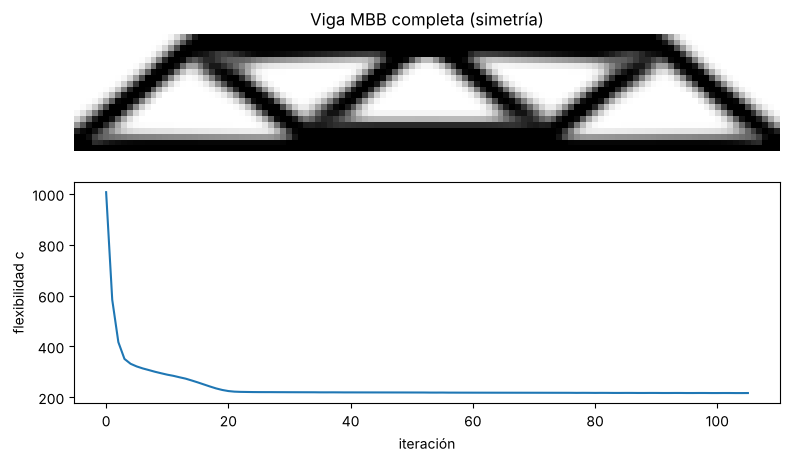

In [14]:
def top88(nelx=60, nely=20, volfrac=0.5, penal=3.0, rmin=1.5, ft=1, tol=0.01, maxit=500):
    nodenrs = np.arange((1 + nelx) * (1 + nely)).reshape(1 + nelx, 1 + nely).T
    edofVec = (2 * nodenrs[:-1, :-1] + 2).flatten(order="F")
    edofMat = edofVec[:, None] + np.array([0, 1, 2*nely + 2, 2*nely + 3, 2*nely, 2*nely + 1, -2, -1])
    iK = np.kron(edofMat, np.ones((8, 1), int)).ravel(); jK = np.kron(edofMat, np.ones((1, 8), int)).ravel()
    ndof = 2 * (nelx + 1) * (nely + 1)
    F = np.zeros(ndof); F[1] = -1.0                                   # carga unitaria hacia abajo, esquina superior izquierda
    fixed = np.union1d(np.arange(0, 2 * (nely + 1), 2), [ndof - 1])   # simetría a la izquierda + apoyo abajo a la derecha
    free = np.setdiff1d(np.arange(ndof), fixed)
    H, Hs = matriz_filtro(nelx, nely, rmin)
    x = np.full(nelx * nely, volfrac); xPhys = x.copy(); hist = []; change = 1.0
    while change > tol and len(hist) < maxit:
        sK = (KE.ravel()[None, :] * simp(xPhys, penal)[:, None]).ravel()
        K = sp.coo_matrix((sK, (iK, jK)), shape=(ndof, ndof)).tocsc(); K = (K + K.T) / 2
        U = np.zeros(ndof); U[free] = spsolve(K[free][:, free], F[free])
        ue = U[edofMat]; ce = np.einsum("ij,jk,ik->i", ue, KE, ue)
        c = float(simp(xPhys, penal) @ ce)
        dc = dsimp_c(xPhys, penal, ce); dv = np.ones_like(x)
        if ft == 1:  dc = H @ (x * dc) / Hs / np.maximum(1e-3, x)       # filtro de sensibilidades
        else:        dc = H @ (dc / Hs); dv = H @ (dv / Hs)             # filtro de densidades (regla de la cadena)
        xnew, xPhys = actualizacion_oc(x, dc, dv, H, Hs, volfrac, ft)
        change = np.abs(xnew - x).max(); x = xnew; hist.append(c)
    return xPhys.reshape(nelx, nely).T, hist

t = time.time()
xMBB, hist = top88(60, 20, 0.5, 3.0, 2.4, ft=1)
print(f"Filtro de sensibilidades, rmin = 2,4: c = {hist[-1]:.2f} tras {len(hist)} iteraciones ({time.time() - t:.1f} s)")
assert abs(hist[-1] - 216.81) < 0.05, "Andreassen et al. (2011, fig. 3) obtienen 216,81"
gris = 4 * np.mean(xMBB * (1 - xMBB))
print(f"Coincide con el valor publicado (216,81). Medida de grises 4·media[x(1−x)] = {gris:.3f}")
fig, ax = plt.subplots(2, 1, figsize=(8, 5))
ax[0].imshow(-np.hstack([np.fliplr(xMBB), xMBB]), cmap="gray"); ax[0].set_title("Viga MBB completa (simetría)"); ax[0].axis("off")
ax[1].plot(hist); ax[1].set_xlabel("iteración"); ax[1].set_ylabel("flexibilidad c"); plt.tight_layout(); plt.show()

In [15]:
# Filtro de densidades (ft = 2) y radio por defecto de la llamada top88(60,20,0.5,3,1.5,1)
xD, hD = top88(60, 20, 0.5, 3.0, 2.4, ft=2)
x15, h15 = top88(60, 20, 0.5, 3.0, 1.5, ft=1)
print(f"densidades, rmin = 2,4: c = {hD[-1]:.2f} (publicado 233,71) · sensibilidades, rmin = 1,5: c = {h15[-1]:.2f}")
assert abs(hD[-1] - 233.71) < 0.05

densidades, rmin = 2,4: c = 233.71 (publicado 233,71) · sensibilidades, rmin = 1,5: c = 203.19


**Ejercicio 7 · Unidades físicas.** El cálculo es adimensional ($E_0=1$, $F=1$, elementos de lado 1). Con aluminio ($E_0=70$ GPa), espesor $t=10$ mm, carga $F=1$ kN en el semimodelo y elementos de 1 mm, la flexibilidad física es $c_{\text{fís}}=\bar c\,F^2/(E_0t)$ (para elementos cuadrados en tensión plana, $K$ escala con $E_0t$). Calcula `c_fis` (J), la flecha bajo la carga `delta` (mm) y la masa del semimodelo `masa` (g, densidad 2,70 g/cm³).

In [16]:
# TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)

c_fis = hist[-1] * 1000.0**2 / (70e9 * 0.010)          # J
delta = c_fis / 1000.0 * 1e3                             # mm  (c = F·δ)
masa = 0.5 * 60 * 20 * 10 * 1e-3 * 2.70                  # g  (60×20 mm, 10 mm de espesor, 50 % de material)

In [17]:
assert abs(c_fis - 0.3097) < 1e-3 and abs(delta - 0.3097) < 1e-3 and abs(masa - 16.2) < 1e-9
print(f"Correcto: c = {c_fis:.4f} J, flecha = {delta:.3f} mm, masa del semimodelo = {masa:.1f} g")

Correcto: c = 0.3097 J, flecha = 0.310 mm, masa del semimodelo = 16.2 g


## Parte 3 · Aleta disipadora con sustituto neuronal (tema 3)

Aleta de aluminio ($k=200$ W/(m·K)) refrigerada por aire forzado ($h=60$ W/(m²·K)) con base a $\theta_b=50$ K sobre el ambiente. Por cada metro de profundidad se dispone de un área de perfil fija $A=60$ mm² (la masa está fijada). El perfil es trapecial: espesor $t(x)=t_b(1-s\,x/L)$, con $t_b=A/(L(1-s/2))$. Por fabricación (extrusión), la punta debe medir al menos 0,3 mm. Variables: longitud $L$ y conicidad $s$.

**El simulador** resuelve por volúmenes finitos $\dfrac{d}{dx}\Bigl(k\,t(x)\dfrac{d\theta}{dx}\Bigr)-2h\theta=0$, $\theta(0)=\theta_b$, punta adiabática, y devuelve el calor $q$ (W por metro de profundidad).

In [18]:
k_al, h_c, th_b, A_perf, t_min = 200.0, 60.0, 50.0, 60e-6, 0.3e-3

def simulador(L, s, N=400):
    tb = A_perf / (L * (1 - s / 2)); dx = L / N
    tf = tb * (1 - s * (np.arange(N) + 0.5) * dx / L)          # espesor en las caras de los volúmenes
    aw = k_al * tf / dx; ae = np.r_[aw[1:], 0.0]
    hw = np.r_[np.full(N - 1, dx), dx / 2]
    ab = np.zeros((3, N)); ab[0, 1:] = -ae[:-1]; ab[1] = aw + ae + 2 * h_c * hw; ab[2, :-1] = -aw[1:]
    rhs = np.zeros(N); rhs[0] = aw[0] * th_b
    th = solve_banded((1, 1), ab, rhs)
    return 2 * h_c * (th_b * dx / 2 + hw @ th)                # calor cedido por convección = calor que entra por la base

def factible(L, s):
    return A_perf / (L * (1 - s / 2)) * (1 - s) >= t_min - 1e-12

**Ejercicio 8.** Para la aleta rectangular ($s=0$) la solución analítica es $q=\sqrt{2hkt}\,\theta_b\tanh(mL)$ con $m=\sqrt{2h/(kt)}$ y $t=A/L$. En los apuntes se demuestra que el óptimo con área fija cumple $\sinh(2\beta)=6\beta$ con $\beta=mL$. Calcula `beta` (con `brentq`), `L_rect`, `t_rect` y `q_rect`.

In [19]:
def q_analitico(L):
    t = A_perf / L; m = np.sqrt(2 * h_c / (k_al * t))
    return np.sqrt(2 * h_c * k_al * t) * th_b * np.tanh(m * L)

# TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
beta = brentq(lambda b: np.sinh(2 * b) - 6 * b, 0.5, 3.0)
cte = np.sqrt(2 * h_c / (k_al * A_perf))         # m = cte · L^{1/2}, luego β = cte · L^{3/2}
L_rect = (beta / cte) ** (2 / 3); t_rect = A_perf / L_rect; q_rect = q_analitico(L_rect)

In [20]:
assert abs(beta - 1.4192) < 1e-4 and abs(L_rect * 1e3 - 58.62) < 0.01
assert abs(simulador(L_rect, 0.0) - q_rect) < 0.01, "el simulador debe reproducir la solución analítica"
print(f"Correcto: β = {beta:.4f}, L = {L_rect*1e3:.2f} mm, t = {t_rect*1e3:.3f} mm, q = {q_rect:.2f} W/m")
print(f"Número de Biot h·t/(2k) = {h_c * t_rect / (2 * k_al):.1e}  (≪ 0,1: el modelo unidimensional es válido)")

Correcto: β = 1.4192, L = 58.62 mm, t = 1.024 mm, q = 220.42 W/m
Número de Biot h·t/(2k) = 1.5e-04  (≪ 0,1: el modelo unidimensional es válido)


### 3b · Sustituto neuronal

Supón que cada simulación cuesta horas (en un caso real sería CFD conjugado). Presupuesto: **40 simulaciones**. Plan: muestreo por hipercubo latino en $L\in[20,100]$ mm y $s\in[0;0{,}9]$ (descartando diseños no fabricables), red MLP 2–32–32–1, validación con 8 puntos reservados, optimización del sustituto en una rejilla de 201 × 201 y **verificación del óptimo con el simulador**.

In [21]:
lo, hi = np.array([20e-3, 0.0]), np.array([100e-3, 0.9])
muestras = lo + qmc.LatinHypercube(d=2, seed=0).random(60) * (hi - lo)
P = muestras[[factible(*p) for p in muestras]][:40]
y = np.array([simulador(*p) for p in P])
Xn = (P - lo) / (hi - lo)
print(len(P), "simulaciones; mejor muestra: q =", round(y.max(), 2), "W/m en L =", round(P[y.argmax(), 0] * 1e3, 1), "mm, s =", round(P[y.argmax(), 1], 3))

40 simulaciones; mejor muestra: q = 238.05 W/m en L = 61.7 mm, s = 0.691


**Ejercicio 9.** Entrena el MLP con 32 puntos (salida tipificada), mide el error RMS en los 8 de validación, reentrena con los 40 y busca el máximo del sustituto en la rejilla factible.

In [22]:
idx = np.random.default_rng(0).permutation(len(Xn)); tr, va = idx[:32], idx[32:]
def nueva_red():
    return make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 32), activation="tanh",
                         max_iter=5000, alpha=1e-4, learning_rate_init=3e-3, random_state=0))
G = np.stack(np.meshgrid(np.linspace(0, 1, 201), np.linspace(0, 1, 201)), -1).reshape(-1, 2)
PG = lo + G * (hi - lo); ok = np.array([factible(*p) for p in PG])

# TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
mu, sd = y.mean(), y.std()
red = nueva_red().fit(Xn[tr], (y[tr] - mu) / sd)
rmse_val = np.sqrt(np.mean((red.predict(Xn[va]) * sd + mu - y[va]) ** 2))
red = nueva_red().fit(Xn, (y - mu) / sd)
qs = red.predict(G) * sd + mu; qs[~ok] = -np.inf
p_sus = PG[np.argmax(qs)]; q_pred = qs.max(); q_ver = simulador(*p_sus)

RMSE de validación = 10.1 W/m (4.9 % de la media)
óptimo del sustituto: L = 62.4 mm, s = 0.815; predicho 242.2 W/m, simulado 242.0 W/m
mejora frente a la aleta rectangular óptima: 9.8 % con 41 simulaciones


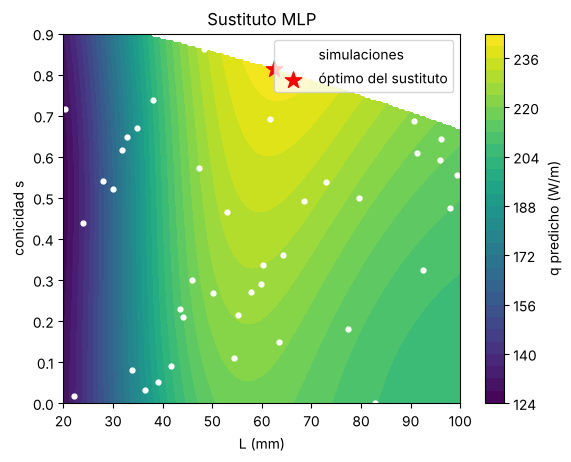

In [23]:
assert rmse_val < 15 and factible(*p_sus)
assert q_ver > y.max(), "el óptimo del sustituto debe mejorar la mejor muestra"
print(f"RMSE de validación = {rmse_val:.1f} W/m ({100*rmse_val/mu:.1f} % de la media)")
print(f"óptimo del sustituto: L = {p_sus[0]*1e3:.1f} mm, s = {p_sus[1]:.3f}; predicho {q_pred:.1f} W/m, simulado {q_ver:.1f} W/m")
print(f"mejora frente a la aleta rectangular óptima: {100*(q_ver/q_rect - 1):.1f} % con 41 simulaciones")
plt.contourf(PG[:, 0].reshape(201, 201)*1e3, PG[:, 1].reshape(201, 201), np.where(ok, qs, np.nan).reshape(201, 201), 30)
plt.colorbar(label="q predicho (W/m)"); plt.scatter(P[:, 0]*1e3, P[:, 1], c="w", s=12, label="simulaciones")
plt.scatter([p_sus[0]*1e3], [p_sus[1]], c="r", marker="*", s=150, label="óptimo del sustituto")
plt.xlabel("L (mm)"); plt.ylabel("conicidad s"); plt.legend(); plt.title("Sustituto MLP"); plt.show()

In [24]:
# Referencia por fuerza bruta (lo que el sustituto pretende evitar): 81 × 96 simulaciones
t = time.time(); mejor = (-1, 0, 0)
for L in np.linspace(0.02, 0.1, 81):
    for s in np.linspace(0, 0.95, 96):
        if factible(L, s):
            q = simulador(L, s)
            if q > mejor[0]: mejor = (q, L, s)
print(f"fuerza bruta: q = {mejor[0]:.2f} W/m en L = {mejor[1]*1e3:.1f} mm, s = {mejor[2]:.3f} ({time.time()-t:.1f} s)")
print(f"el sustituto queda a {100*(1 - q_ver/mejor[0]):.2f} % del mejor diseño de la rejilla")

fuerza bruta: q = 242.11 W/m en L = 66.0 mm, s = 0.800 (0.6 s)
el sustituto queda a 0.03 % del mejor diseño de la rejilla


### 3c · Simulador diferenciable

En lugar de aprender un sustituto, se puede derivar el propio simulador. Reescribimos el solver en torch (sistema denso, $N=200$) y `autograd` calcula $\partial q/\partial(L,s)$, que por dentro es el método adjunto: una resolución del sistema transpuesto. La restricción de la punta se impone por **proyección** tras cada paso: $s\le s_{\max}(L)=(1-r)/(1-r/2)$ con $r=t_{\min}L/A$.

**Ejercicio 10.** Completa el paso de ascenso de gradiente con Adam y la proyección.

In [25]:
torch.set_default_dtype(torch.float64)
def simulador_t(L, s, N=200):
    tb = A_perf / (L * (1 - s / 2)); dx = L / N
    tf = tb * (1 - s * (torch.arange(N) + 0.5) * dx / L)
    aw = k_al * tf / dx; ae = torch.cat([aw[1:], torch.zeros(1)])
    hw = torch.cat([torch.ones(N - 1), torch.tensor([0.5])]) * dx
    K = torch.diag(aw + ae + 2 * h_c * hw) - torch.diag(aw[1:], -1) - torch.diag(ae[:-1], 1)
    rhs = torch.zeros(N); rhs[0] = 1.0
    th = torch.linalg.solve(K, rhs * aw[0] * th_b)
    return 2 * h_c * (th_b * dx / 2 + (hw * th).sum())

def s_max(L):
    r = t_min * L / A_perf
    return (1 - r) / (1 - r / 2)

# comprobación del gradiente frente a diferencias finitas
L0 = torch.tensor(0.05, requires_grad=True); q0 = simulador_t(L0, torch.tensor(0.3)); q0.backward()
fd = (simulador_t(torch.tensor(0.05 + 1e-6), torch.tensor(0.3)) - simulador_t(torch.tensor(0.05 - 1e-6), torch.tensor(0.3))) / 2e-6
print(f"∂q/∂L: autograd {L0.grad.item():.4f} · diferencias finitas {fd.item():.4f} W/m²")

∂q/∂L: autograd 1193.7582 · diferencias finitas 1193.7581 W/m²


In [26]:
z = torch.tensor([0.40, 0.0], requires_grad=True)       # (L en décimas de metro, s)
opt = torch.optim.Adam([z], lr=0.02); tray = []
for it in range(150):
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    q = simulador_t(z[0] * 0.1, z[1])
    opt.zero_grad(); (-q).backward(); opt.step()
    with torch.no_grad():
        z[0].clamp_(0.2, 1.0)
        z[1].clamp_(0.0, min(0.95, s_max(z[0].item() * 0.1)))
    tray.append((z[0].item() * 100, z[1].item(), q.item()))
L_d, s_d = z[0].item() * 0.1, z[1].item(); q_d = simulador(L_d, s_d)

Correcto: gradiente proyectado → L = 66.3 mm, s = 0.801, q = 242.16 W/m (150 evaluaciones con gradiente)
espesor en la punta = 0.300 mm: la restricción de fabricación está activa


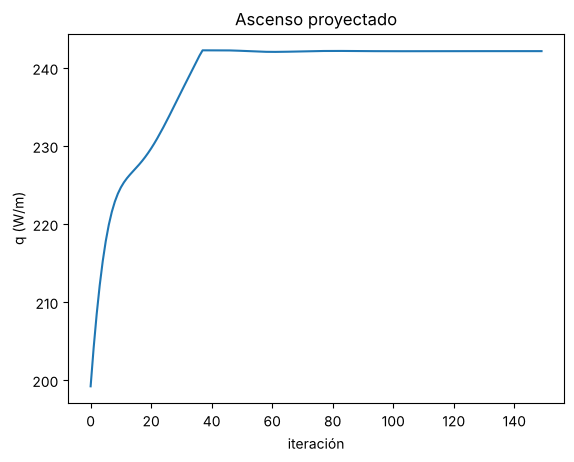

In [27]:
assert abs(q_d - mejor[0]) / mejor[0] < 0.005 and factible(L_d, s_d)
print(f"Correcto: gradiente proyectado → L = {L_d*1e3:.1f} mm, s = {s_d:.3f}, q = {q_d:.2f} W/m (150 evaluaciones con gradiente)")
print(f"espesor en la punta = {A_perf/(L_d*(1-s_d/2))*(1-s_d)*1e3:.3f} mm: la restricción de fabricación está activa")
tr_ = np.array(tray); plt.plot(tr_[:, 2]); plt.xlabel("iteración"); plt.ylabel("q (W/m)"); plt.title("Ascenso proyectado"); plt.show()

## Parte 4 · Ajuste de una forma a siluetas (tema 4)

Forma estrellada: el radio en la dirección $\hat x$ es $r(\hat x)=\exp\bigl(\sum_{\ell\le 3}\sum_m c_{\ell m}Y_{\ell m}(\hat x)\bigr)$, con 16 coeficientes de armónicos esféricos reales. Unidad de longitud: 20 mm (el volumen de trabajo $[-1,1]^3$ es un cubo de 40 mm). Se observan **6 siluetas** de 40 × 40 píxeles desde orientaciones aleatorias, con 40 muestras por rayo (proyección ortográfica).

Ocupación suave: $o(x)=\sigma\bigl((r(\hat x)-\lVert x\rVert)/\tau\bigr)$. Silueta suave de un rayo (agregación de SoftRas): $S=1-\prod_k\bigl(1-o(x_k)\bigr)$.

In [28]:
LMAX = 3
def base_ae(d):
    th = np.arccos(np.clip(d[:, 2], -1, 1)); ph = np.arctan2(d[:, 1], d[:, 0]); cols = []
    for l in range(LMAX + 1):
        for m in range(-l, l + 1):
            Y = sph_harm_y(l, abs(m), th, ph)
            cols.append(np.sqrt(2) * (-1)**m * Y.imag if m < 0 else (Y.real if m == 0 else np.sqrt(2) * (-1)**m * Y.real))
    return np.stack(cols, 1)

NP, NS, NV = 40, 40, 6
g1 = np.linspace(-1, 1, NP); gz = np.linspace(-1, 1, NS)
pts = np.stack(np.meshgrid(g1, g1, gz, indexing="ij"), -1).reshape(-1, 3)   # rayos paralelos al eje z de la cámara
B, R = [], []
for rot in Rotation.random(NV, random_state=1):
    Xw = rot.apply(pts); rr = np.linalg.norm(Xw, axis=1) + 1e-9
    B.append(base_ae(Xw / rr[:, None])); R.append(rr)
B = torch.tensor(np.stack(B)); R = torch.tensor(np.stack(R))
rng = np.random.default_rng(3)
c_obj = np.zeros(16); c_obj[0] = np.log(0.55) * np.sqrt(4 * np.pi)
c_obj[1:] = rng.normal(0, 0.18, 15) * np.repeat(np.arange(1, LMAX + 1), [3, 5, 7]) ** -0.5
c_obj = torch.tensor(c_obj)
print("base:", tuple(B.shape), "· radio medio del objetivo ≈", round(0.55 * 20, 1), "mm")

base: (6, 64000, 16) · radio medio del objetivo ≈ 11.0 mm


**Ejercicio 11.** Implementa `render(c, tau)`: radios, ocupación suave (recorta a $1-10^{-6}$) y silueta agregada en forma logarítmica estable $S=1-\exp\bigl(\sum_k\log(1-o_k)\bigr)$.

In [29]:
def render(c, tau):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    r = torch.exp(B @ c)
    o = torch.sigmoid((r - R) / tau).clamp(max=1 - 1e-6)
    return 1 - torch.exp(torch.log1p(-o).reshape(NV, NP, NP, NS).sum(-1))

def iou_suave(S, T):
    return (S * T).sum() / (S + T - S * T).sum()

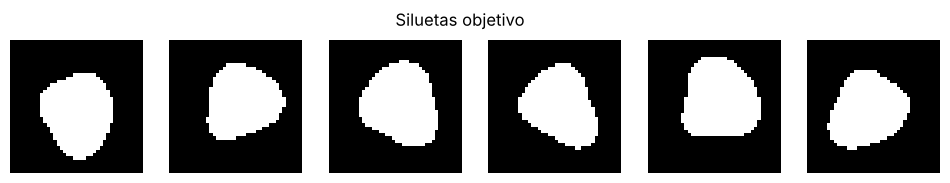

Correcto: fracción de píxeles ocupados = 0.272


In [30]:
with torch.no_grad():
    objetivo = (render(c_obj, 0.005) > 0.5).double()          # máscaras binarias, como las de una segmentación
assert objetivo.shape == (6, 40, 40) and 0.2 < objetivo.mean() < 0.6
fig, ax = plt.subplots(1, 6, figsize=(12, 2))
for i in range(6): ax[i].imshow(objetivo[i], cmap="gray"); ax[i].axis("off")
plt.suptitle("Siluetas objetivo"); plt.show()
print("Correcto: fracción de píxeles ocupados =", round(objetivo.mean().item(), 3))

**Ejercicio 12.** Ajusta los 16 coeficientes minimizando $1-\mathrm{IoU}_{\text{suave}}$ con Adam (lr 0,03, 300 iteraciones), partiendo de una esfera de radio 8 mm. Compara $\tau$ fijo (0,03) con un **recocido** geométrico de $\tau$ desde 0,05 hasta 0,005.

In [31]:
gg = np.linspace(-1, 1, 64); GX = np.stack(np.meshgrid(gg, gg, gg, indexing="ij"), -1).reshape(-1, 3)
rg = np.linalg.norm(GX, axis=1) + 1e-9; Bg = torch.tensor(base_ae(GX / rg[:, None]))
def iou_3d(c):
    with torch.no_grad():
        a = torch.exp(Bg @ c_obj).numpy() > rg; b = torch.exp(Bg @ c).numpy() > rg
    return (a & b).sum() / (a | b).sum()

def ajustar(recocido, iters=300, lr=0.03):
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    c = torch.zeros(16); c[0] = np.log(0.4) * np.sqrt(4 * np.pi); c.requires_grad_(True)
    opt = torch.optim.Adam([c], lr=lr)
    for it in range(iters):
        tau = 0.05 * (0.1 ** (it / (iters - 1))) if recocido else 0.03
        perdida = 1 - iou_suave(render(c, tau), objetivo)
        opt.zero_grad(); perdida.backward(); opt.step()
    with torch.no_grad():
        S = (render(c, 0.005) > 0.5).double()
    return c.detach(), (S * objetivo).sum().item() / ((S + objetivo) > 0).sum().item()

τ fijo:    IoU 2D = 0.827 · IoU 3D = 0.744
recocido:  IoU 2D = 0.995 · IoU 3D = 0.991   (7.0 s en total)
Correcto: con τ fijo la silueta suave se 'hincha' y el ajuste encoge la forma; el recocido elimina el sesgo.


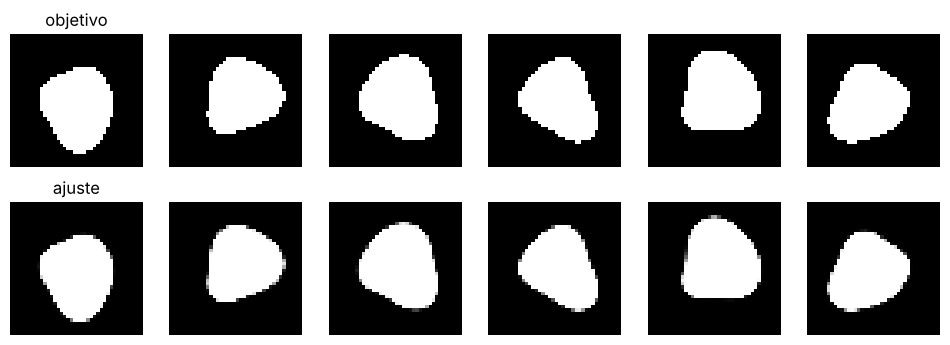

In [32]:
t = time.time()
c_fijo, iou2_fijo = ajustar(False); c_rec, iou2_rec = ajustar(True)
print(f"τ fijo:    IoU 2D = {iou2_fijo:.3f} · IoU 3D = {iou_3d(c_fijo):.3f}")
print(f"recocido:  IoU 2D = {iou2_rec:.3f} · IoU 3D = {iou_3d(c_rec):.3f}   ({time.time()-t:.1f} s en total)")
assert iou2_rec > 0.98 and iou_3d(c_rec) > 0.97 and iou2_rec > iou2_fijo
print("Correcto: con τ fijo la silueta suave se 'hincha' y el ajuste encoge la forma; el recocido elimina el sesgo.")
with torch.no_grad(): S_rec = render(c_rec, 0.005)
fig, ax = plt.subplots(2, 6, figsize=(12, 4))
for i in range(6):
    ax[0, i].imshow(objetivo[i], cmap="gray"); ax[1, i].imshow(S_rec[i], cmap="gray"); ax[0, i].axis("off"); ax[1, i].axis("off")
ax[0, 0].set_title("objetivo"); ax[1, 0].set_title("ajuste"); plt.show()

## Parte 5 · Pipelines de software 3D (tema 5)

### 5a · Simplificación por error cuádrico (Garland y Heckbert, 1997)

Cada cara con plano $n^\top x+d=0$ ($\lVert n\rVert=1$) aporta la cuádrica fundamental $K_p=pp^\top$, $p=(n,d)$. La cuádrica de un vértice es la suma sobre sus caras, y el error de colocarlo en $v$ es $\Delta(v)=\bar v^\top Q\,\bar v$ con $\bar v=(v,1)$.

**Ejercicio 13.** Escribe `cuadricas_vertices(V, F)` y `posicion_optima(Q, v1, v2)` (resuelve el sistema lineal del artículo; si es singular, prueba $v_1$, $v_2$ y el punto medio).

In [33]:
def esfera_uv(nu=24, nv=12):
    V = [[0, 0, 1]]
    for i in range(1, nv):
        th = np.pi * i / nv
        V += [[np.sin(th) * np.cos(2*np.pi*j/nu), np.sin(th) * np.sin(2*np.pi*j/nu), np.cos(th)] for j in range(nu)]
    V.append([0, 0, -1]); V = np.array(V); F = []
    anillo = lambda i, j: 1 + (i - 1) * nu + (j % nu)
    F += [[0, anillo(1, j), anillo(1, j + 1)] for j in range(nu)]
    for i in range(1, nv - 1):
        for j in range(nu):
            a, b, c, d = anillo(i, j), anillo(i, j + 1), anillo(i + 1, j), anillo(i + 1, j + 1); F += [[a, c, b], [b, c, d]]
    F += [[len(V) - 1, anillo(nv - 1, j + 1), anillo(nv - 1, j)] for j in range(nu)]
    return V, np.array(F)

def planos(V, F):
    n = np.cross(V[F[:, 1]] - V[F[:, 0]], V[F[:, 2]] - V[F[:, 0]]); n /= np.linalg.norm(n, axis=1, keepdims=True)
    return np.c_[n, -(n * V[F[:, 0]]).sum(1)]

def cuadricas_vertices(V, F):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    P = planos(V, F); K = P[:, :, None] * P[:, None, :]; Q = np.zeros((len(V), 4, 4))
    for k in range(3): np.add.at(Q, F[:, k], K)
    return Q

def posicion_optima(Q, v1, v2):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    A = Q.copy(); A[3] = [0, 0, 0, 1]
    if np.linalg.cond(A) < 1e10:
        x = np.linalg.solve(A, [0, 0, 0, 1.0])
    else:
        x = min([np.r_[v1, 1], np.r_[v2, 1], np.r_[(v1 + v2) / 2, 1]], key=lambda z: z @ Q @ z)
    return x[:3], float(x @ Q @ x)

In [34]:
# Comprobación: la esquina de un cubo (tres planos ortogonales) se recupera exactamente con error nulo
Vc = np.array([[0., 0, 0], [1, 0, 0], [0, 1, 0], [0, 0, 1]])
Fc = np.array([[0, 2, 1], [0, 1, 3], [0, 3, 2]])          # caras en los planos z = 0, y = 0, x = 0
Qc = cuadricas_vertices(Vc, Fc)
v_opt, err = posicion_optima(Qc[0] + Qc[1], Vc[0], Vc[1])
assert np.allclose(v_opt, 0, atol=1e-12) and err < 1e-20
# error de mover el vértice a (0,1; 0,2; 0,3): suma de distancias al cuadrado a los tres planos
p = np.r_[0.1, 0.2, 0.3, 1]; assert abs(p @ Qc[0] @ p - (0.01 + 0.04 + 0.09)) < 1e-12
print("Correcto: posición óptima", v_opt, "· Δ(0,1; 0,2; 0,3) =", round(p @ Qc[0] @ p, 4))

Correcto: posición óptima [0. 0. 0.] · Δ(0,1; 0,2; 0,3) = 0.14


Con estas piezas, el bucle voraz con montículo (colapsa la arista de menor coste y actualiza vecinos):

In [35]:
def simplificar(V, F, objetivo_caras):
    V = V.copy(); F = [list(f) for f in F]; Q = cuadricas_vertices(V, np.array(F)); viva = np.ones(len(F), bool)
    caras_de = [set() for _ in V]
    for i, f in enumerate(F):
        for v in f: caras_de[v].add(i)
    version = np.zeros(len(V), int); monticulo = []
    vecinos = lambda v: {u for fi in caras_de[v] for u in F[fi] if u != v}
    def empujar(a, b):
        x, c = posicion_optima(Q[a] + Q[b], V[a], V[b]); heapq.heappush(monticulo, (c, a, b, version[a], version[b], tuple(x)))
    for a in range(len(V)):
        for b in vecinos(a):
            if a < b: empujar(a, b)
    n_caras = len(F)
    while n_caras > objetivo_caras and monticulo:
        c, a, b, va, vb, x = heapq.heappop(monticulo)
        if version[a] != va or version[b] != vb: continue          # entrada obsoleta
        V[a] = x; Q[a] = Q[a] + Q[b]; version[a] += 1; version[b] += 1
        for fi in list(caras_de[b]):
            if a in F[fi]:
                viva[fi] = False; n_caras -= 1
                for u in F[fi]: caras_de[u].discard(fi)
            else:
                F[fi] = [a if u == b else u for u in F[fi]]; caras_de[a].add(fi)
        caras_de[b] = set()
        for u in vecinos(a): empujar(min(a, u), max(a, u))
    Fv = np.array([F[i] for i in range(len(F)) if viva[i]]); usados = np.unique(Fv)
    nuevo = -np.ones(len(V), int); nuevo[usados] = np.arange(len(usados))
    return V[usados], nuevo[Fv]

V0, F0 = esfera_uv()
print("malla original:", len(V0), "vértices,", len(F0), "caras")
for nf in (400, 200, 100):
    V1, F1 = simplificar(V0, F0, nf)
    dev = np.abs(np.linalg.norm(V1, axis=1) - 1).max()
    print(f"  {len(F1):4d} caras · {len(V1):4d} vértices · χ = {len(V1) - 3*len(F1)//2 + len(F1)} · desviación máx. de vértices = {dev*20:.3f} mm (esfera de 20 mm)")

malla original: 266 vértices, 528 caras
   400 caras ·  202 vértices · χ = 2 · desviación máx. de vértices = 0.084 mm (esfera de 20 mm)
   200 caras ·  102 vértices · χ = 2 · desviación máx. de vértices = 0.301 mm (esfera de 20 mm)


   100 caras ·   52 vértices · χ = 2 · desviación máx. de vértices = 0.717 mm (esfera de 20 mm)


### 5b · Niveles de detalle con presupuesto de milisegundos

A 60 Hz hay 16,67 ms por fotograma. El equipo reserva **4,0 ms** de GPU para cuatro grupos de objetos. Cada grupo admite LOD0–LOD3 con coste (ms) y error en pantalla (px); el error se pondera por la importancia visual del grupo. Es una **mochila de elección múltiple**.

In [36]:
grupos = {  # peso, [(ms, px) para LOD0..LOD3]
    "árboles":    (1.0, [(3.20, 0.0), (1.70, 0.6), (0.90, 1.5), (0.45, 4.0)]),
    "rocas":      (0.5, [(2.40, 0.0), (1.30, 0.4), (0.70, 1.2), (0.35, 3.0)]),
    "edificios":  (1.5, [(1.80, 0.0), (1.00, 0.3), (0.55, 0.9), (0.30, 2.5)]),
    "personajes": (3.0, [(1.20, 0.0), (0.70, 0.5), (0.40, 1.6), (0.25, 4.5)]),
}
nombres, PRES = list(grupos), 4.0
coste = lambda e: sum(grupos[n][1][i][0] for n, i in zip(nombres, e))
error = lambda e: sum(grupos[n][0] * grupos[n][1][i][1] for n, i in zip(nombres, e))
print("todo en LOD0:", round(coste((0, 0, 0, 0)), 2), "ms > 4,0 ms")

todo en LOD0: 8.6 ms > 4,0 ms


**Ejercicio 14.** Resuelve el problema exactamente por enumeración ($4^4$ combinaciones) y mediante la relajación lagrangiana $\min_e \sum_g w_g\,\text{err}_g+\lambda(\text{coste}-4)$ para $\lambda\in\{0; 0{,}25; \dots; 6\}$. Guarda la mejor cota dual `cota`.

In [37]:
# TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)

factibles = [e for e in itertools.product(range(4), repeat=4) if coste(e) <= PRES + 1e-12]
e_opt = min(factibles, key=error)
cota, e_lag = -np.inf, None
for lam in np.arange(0, 6.001, 0.25):
    e = tuple(min(range(4), key=lambda i: grupos[n][0] * grupos[n][1][i][1] + lam * grupos[n][1][i][0]) for n in nombres)
    dual = error(e) + lam * (coste(e) - PRES)
    if dual > cota: cota, e_lag, lam_opt = dual, e, lam

In [38]:
assert e_opt == (2, 2, 1, 0) and abs(error(e_opt) - 2.55) < 1e-12
assert cota <= error(e_opt) + 1e-12
print(f"óptimo exacto: LOD {dict(zip(nombres, e_opt))}, {coste(e_opt):.2f} ms, error ponderado {error(e_opt):.2f}")
print(f"relajación lagrangiana: λ = {lam_opt}, cota inferior {cota:.2f} (hueco {error(e_opt) - cota:.2f}); su elección {e_lag} coincide con el óptimo")

óptimo exacto: LOD {'árboles': 2, 'rocas': 2, 'edificios': 1, 'personajes': 0}, 3.80 ms, error ponderado 2.55
relajación lagrangiana: λ = 1.25, cota inferior 2.30 (hueco 0.25); su elección (2, 2, 1, 0) coincide con el óptimo


**Ejercicio 15 · Memoria de texturas.** Calcula en MiB la memoria de una textura de 4096 × 4096 con la cadena completa de mipmaps (factor 4/3) en RGBA8 (32 bits/texel), BC7 (8 bits/texel) y BC1 (4 bits/texel).

In [39]:
# TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)

texeles = 4096 * 4096
mib = {fmt: texeles * bpp / 8 * 4 / 3 / 2**20 for fmt, bpp in [("RGBA8", 32), ("BC7", 8), ("BC1", 4)]}

In [40]:
assert abs(mib["RGBA8"] - 85.333) < 1e-3 and abs(mib["BC7"] - 21.333) < 1e-3 and abs(mib["BC1"] - 10.667) < 1e-3
print("Correcto:", {k: round(v, 2) for k, v in mib.items()}, "MiB")

Correcto: {'RGBA8': 85.33, 'BC7': 21.33, 'BC1': 10.67} MiB


## Parte 6 · Validación de mallas generadas (tema 6)

Un generador ha producido un cubo de 40 mm centrado en el origen (12 triángulos). Validamos tres versiones: la correcta, una a la que le falta un triángulo y otra con un triángulo con la orientación invertida.

**Ejercicio 16.** Escribe `validar(V, F)`, que devuelva: número de aristas, aristas de borde (una cara), aristas no variedad (más de dos caras), aristas dirigidas repetidas (orientación inconsistente), característica de Euler y volumen con signo $\tfrac16\sum_f \det(v_a,v_b,v_c)$.

In [41]:
a = 20.0
Vcubo = np.array([[x, y, z] for x in (-a, a) for y in (-a, a) for z in (-a, a)])
Fcubo = np.array([[0, 1, 3], [0, 3, 2], [4, 6, 7], [4, 7, 5], [0, 4, 5], [0, 5, 1],
                  [2, 3, 7], [2, 7, 6], [0, 2, 6], [0, 6, 4], [1, 5, 7], [1, 7, 3]])

def validar(V, F):
    
    # TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)
    from collections import Counter
    dirigidas = Counter((int(f[i]), int(f[(i + 1) % 3])) for f in F for i in range(3))
    no_dir = Counter(tuple(sorted(e)) for e in dirigidas.elements())
    vol = sum(np.linalg.det(V[f]) for f in F) / 6
    return dict(aristas=len(no_dir), borde=sum(c == 1 for c in no_dir.values()),
                no_variedad=sum(c > 2 for c in no_dir.values()),
                dirigidas_repetidas=sum(c > 1 for c in dirigidas.values()),
                euler=len(np.unique(F)) - len(no_dir) + len(F), volumen=vol)

In [42]:
ok_, falta, girada = validar(Vcubo, Fcubo), validar(Vcubo, Fcubo[1:]), validar(Vcubo, np.r_[Fcubo[:1, ::-1], Fcubo[1:]])
for nombre, r in [("correcta", ok_), ("falta 1 cara", falta), ("1 cara girada", girada)]:
    print(f"{nombre:14s}", {k: (round(v) if k == 'volumen' else v) for k, v in r.items()})
assert ok_["borde"] == 0 and ok_["euler"] == 2 and abs(ok_["volumen"] - 64000) < 1e-6
assert falta["borde"] == 3 and falta["euler"] == 1
assert girada["dirigidas_repetidas"] == 3 and abs(girada["volumen"] - 64000 * 5 / 6) < 1e-6
print("Correcto: la cara girada no abre agujeros, pero la delatan las aristas dirigidas repetidas y el volumen (5/6 del real).")

correcta       {'aristas': 18, 'borde': 0, 'no_variedad': 0, 'dirigidas_repetidas': 0, 'euler': 2, 'volumen': 64000}
falta 1 cara   {'aristas': 18, 'borde': 3, 'no_variedad': 0, 'dirigidas_repetidas': 0, 'euler': 1, 'volumen': 58667}
1 cara girada  {'aristas': 18, 'borde': 0, 'no_variedad': 0, 'dirigidas_repetidas': 3, 'euler': 2, 'volumen': 53333}
Correcto: la cara girada no abre agujeros, pero la delatan las aristas dirigidas repetidas y el volumen (5/6 del real).


**Ejercicio 17 · Voladizos.** Para imprimir en la dirección $+z$, una cara necesita soporte si mira hacia abajo con un ángulo respecto a la horizontal menor que 45°, es decir, si $n_z<-\cos 45^\circ$. Inclina el cubo 30° alrededor del eje $x$ y calcula la fracción del área que necesita soporte (sin contar la que apoya en la bandeja).

In [43]:
# TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)

Rx = Rotation.from_euler("x", 30, degrees=True).as_matrix()
Vr = Vcubo @ Rx.T
n_ = np.cross(Vr[Fcubo[:, 1]] - Vr[Fcubo[:, 0]], Vr[Fcubo[:, 2]] - Vr[Fcubo[:, 0]])
area = np.linalg.norm(n_, axis=1) / 2; n_ = n_ / (2 * area[:, None])
zc = Vr[Fcubo].mean(1)[:, 2]
necesita = (n_[:, 2] < -np.cos(np.radians(45))) & (zc > Vr[:, 2].min() + 1e-9)   # caras que miran abajo y no están en la bandeja
frac_soporte = area[necesita].sum() / area.sum()

In [44]:
print("normales z:", np.unique(n_[:, 2].round(3)))
assert abs(frac_soporte - 1 / 6) < 1e-9
print(f"Correcto: {100*frac_soporte:.1f} % del área necesita soporte. Al inclinar 30°, dos caras quedan hacia abajo con n_z = −0,866 y −0,5:")
print("la primera forma 30° con la horizontal y exige soporte; la segunda forma 60° y se autosoporta.")

normales z: [-0.866 -0.5    0.     0.5    0.866]
Correcto: 16.7 % del área necesita soporte. Al inclinar 30°, dos caras quedan hacia abajo con n_z = −0,866 y −0,5:
la primera forma 30° con la horizontal y exige soporte; la segunda forma 60° y se autosoporta.


**Ejercicio 18 · Lo mejor de N.** Si cada malla generada supera la validación con probabilidad independiente $p=0{,}3$, ¿cuántas hay que generar para obtener al menos una válida con probabilidad ≥ 95 %?

In [45]:
# TU CÓDIGO (la versión guardada trae la solución de referencia: bórrala e inténtalo)

N_min = int(np.ceil(np.log(0.05) / np.log(1 - 0.3)))

In [46]:
assert N_min == 9 and 1 - 0.7**N_min >= 0.95 > 1 - 0.7**(N_min - 1)
print(f"Correcto: N = {N_min} (probabilidad {1 - 0.7**N_min:.4f}; con 8 sería {1 - 0.7**8:.4f})")
print(f"Tiempo total del cuaderno: {time.time() - T0:.1f} s")

Correcto: N = 9 (probabilidad 0.9596; con 8 sería 0.9424)
Tiempo total del cuaderno: 17.3 s


## Parte 7 · Retos

1. **Ménsula en voladizo.** Cambia las condiciones de contorno de `top88` para empotrar todo el borde izquierdo y cargar el punto medio del borde derecho (Andreassen *et al.*, §5.1 usan `top88(160,100,0.4,3,6,1)`). Pista: `fixed = np.arange(2*(nely+1))`.
2. **Proyección de Heaviside.** Añade $\bar x=1-e^{-\beta\tilde x}+\tilde x e^{-\beta}$ con continuación en β y mide la medida de grises.
3. **Sustituto con incertidumbre.** Sustituye el MLP por un proceso gaussiano (`sklearn.gaussian_process`) y añade puntos con mejora esperada. ¿Cuántas simulaciones necesitas para quedar a menos del 0,5 %?
4. **Casco visual.** Crea un objetivo con una concavidad profunda (por ejemplo, $c_{20}$ muy negativo) y comprueba que la IoU 3D se estanca aunque la IoU 2D sea casi 1. ¿Por qué?
5. **Inversión de caras con QEM.** Añade a `simplificar` un test que rechace colapsos que invierten la normal de alguna cara vecina.
6. **Validador completo.** Añade a `validar` el espesor mínimo de pared muestreando la SDF de la malla.

---
### Soluciones de referencia
Inténtalo antes de mirar. (En la versión guardada ya están dentro de las celdas `# TU CÓDIGO`.)

In [47]:
# --- Ejercicio 1 ---
# def sdf_esfera(x, c, r): return np.linalg.norm(x - c, axis=-1) - r
# def sdf_caja(x, b):
#     q = np.abs(x) - b
#     return np.linalg.norm(np.maximum(q, 0), axis=-1) + np.minimum(q.max(axis=-1), 0)
# --- Ejercicio 2 ---
# A = np.c_[2 * X, np.ones(len(X))]; b = (X**2).sum(1); sol = np.linalg.lstsq(A, b, rcond=None)[0]
# c = sol[:3]; r = np.sqrt(sol[3] + c @ c)
# --- Ejercicio 3 ---
# D = X - c; nr = np.linalg.norm(D, axis=1); res = nr - r; J = np.c_[-D / nr[:, None], -np.ones(len(X))]
# dp = np.linalg.lstsq(J, -res, rcond=None)[0]   (repetir hasta que ||dp|| < tol)
# --- Ejercicio 4 ---
# simp = Emin + xf**p * (E0 - Emin);  dsimp_c = -p * (E0 - Emin) * xf**(p - 1) * ce
# --- Ejercicio 5 ---
# H_ei = max(0, rmin - hypot(Δi, Δj)) para los vecinos en una ventana de radio ceil(rmin) - 1; Hs = H.sum(1)
# --- Ejercicio 6 ---
# bisección en λ: xnew = clip(x*sqrt(-dc/dv/λ), x-move, x+move) ∩ [0,1]; subir λ si sobra volumen
# --- Ejercicio 7 ---
# c_fis = 216.81 * 1e6 / (70e9 * 0.01) = 0.3097 J; delta = c_fis / F = 0.3097 mm; masa = 6 cm³ · 2.70 = 16.2 g
# --- Ejercicio 8 ---
# beta = brentq(lambda b: np.sinh(2*b) - 6*b, 0.5, 3); L = (beta / sqrt(2h/(kA)))**(2/3)
# --- Ejercicio 9 ---
# red.fit(Xn[tr], (y[tr]-mu)/sd); rmse en va; red.fit(Xn, ...); argmax de la predicción en la rejilla factible; simulador(*p)
# --- Ejercicio 10 ---
# q = simulador_t(z[0]*0.1, z[1]); opt.zero_grad(); (-q).backward(); opt.step(); proyectar s en [0, min(0.95, s_max(L))]
# --- Ejercicio 11 ---
# r = exp(B @ c); o = sigmoid((r - R)/tau).clamp(max=1-1e-6); S = 1 - exp(sum log1p(-o) a lo largo del rayo)
# --- Ejercicio 12 ---
# tau = 0.05 * 0.1**(it/(iters-1)) (recocido) o 0.03; pérdida = 1 - iou_suave(render(c, tau), objetivo); Adam
# --- Ejercicio 13 ---
# K = p p^T por cara; Q_v = suma sobre caras; resolver [Q_11 Q_12 Q_13 Q_14; ...; 0 0 0 1] v = (0,0,0,1)
# --- Ejercicio 14 ---
# enumeración de itertools.product(range(4), repeat=4) con coste <= 4; dual(λ) = min_e [error + λ(coste - 4)]
# --- Ejercicio 15 ---
# 4096² · bpp/8 · 4/3 bytes: 85,33 / 21,33 / 10,67 MiB
# --- Ejercicio 16 ---
# contar aristas dirigidas (a,b); una arista no dirigida con 1 cara es de borde; (a,b) repetida = orientación incoherente
# --- Ejercicio 17 ---
# normales tras girar 30°; soporte si n_z < -cos 45° y la cara no está apoyada en la bandeja
# --- Ejercicio 18 ---
# N = ceil(ln 0.05 / ln 0.7) = 9